# Selective Superadinace Experiment in an Inverted Atom Cloud
- the goal of this notebook is to illustrate the competition between two radiative channels in the presence of collective enhacement for both channels. One channel is radation into freespace, and the other is radiation in a nearby resonant cavity. This is illustrated in the diagram from this [paper](https://journals.aps.org/prl/abstract/10.1103/cdd5-r7h4).


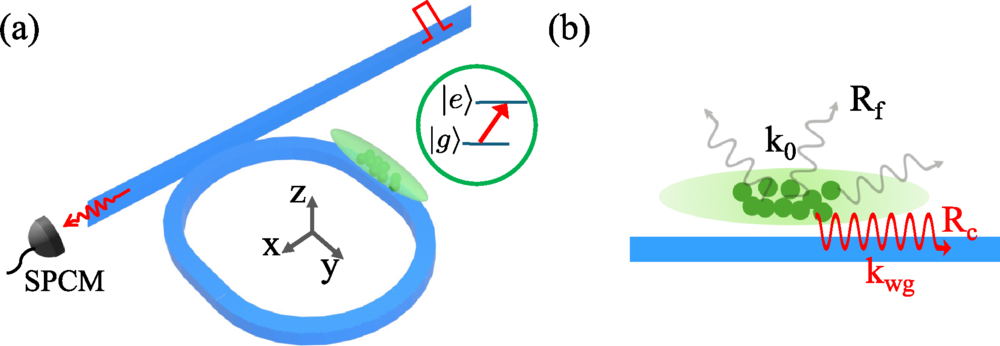


- This is a joint effort between a theory and experiment groups at Purdue University. The experiment is currently underway at Chen Lung Hung's AMO lab with Mohamed Eltohfa being responsible for computational modelling.
- Selective superadinace was illustrated in previous work in the low intensity limit, where at most one atom is excited. These results were puplished into a theory paper ([Collective emission and selective radiance in atomic clouds and arrays coupled to a microring resonator](https://journals.aps.org/pra/abstract/10.1103/q8rz-8g2h)) and a companion experimental paper ([Selective Collective Emission from a Dense Atomic Ensemble Coupled to a Nanophotonic Resonator](https://journals.aps.org/prl/abstract/10.1103/cdd5-r7h4)) also carried out at Purdue by previous students at the same groups.
- The new experiment aims to illustrate selective radiance but in the maximally inverted scenario (which happens in the large intensity regime).

## 1) Initializing Compute Enviroment

In [1]:
# imports
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
import save_data as sd
from mf2_func import *
import atom_recoil_func as ar
import time
import os
import psutil
from joblib import cpu_count, Parallel, delayed
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # needed for 3D projection

In [2]:
# memory and cpu info
# used to check the number of cores avaialble for parallel processing and the memory usage of the program
# parallel processing is going to be used later to speed up the computation of the ODE solver for large atom numbers
num_cores = cpu_count()
print("Max available CPU cores:", num_cores)
process = psutil.Process(os.getpid())
print("Current memory usage (MB):", process.memory_info().rss / 1024 / 1024)

Max available CPU cores: 8
Current memory usage (MB): 204.03125


In [3]:
# seeding the random number generator for reproducibility
# change the seed to a different value to get different realization of the system below
seed = 0
rng = np.random.default_rng(int(seed) if seed else 42)


## 2) Atomic system initializtion
- here we have $N$ atoms in a cloud which is prepared in the viscinity of a microring cavity. 
- The microring has a resonant wavelength which is 1.7 shorter than the freespace resonance of the atomic transition
- The cloud has characteristic shape as set up in the code. The following code initializes the system and visualizes the cloud near the microring
- in the code, we assume natural units, where the transition decay rate into freespace is $\Gamma_{fs} = 1$, and the wavelength in freespace is $\lambda_{fs} = 1$

In [4]:
# cloud parameters
kf = 2 * np.pi # freespace wavevector
kwg = kf * 1.7 # wavevector in the waveguide
N = 18 # number of qubits    
um = 1000/852 # um per wavelength for 852 nm light
ring_circum = 120 * um # ring circumference
ring_radius = ring_circum/(2*np.pi) # ring radius
rms_along_ring = 2 * um # rms of atom position along the ring direction
rms_transverse = 0.1 * um # 100nm rms of atom position in the transverse direction in the plane of the waveguide
mu, sigma, x0 = 5.872397346578346, 0.6429754153791893, 136.40400859972002 # parameters for the lognormal distribution of the position perpendicular to the plane of the waveguide. # these parameters are in nm # wavelength in freespace is 852 nm # we will consider the effect of this distribution on the selective supperadiance later in the code.
lambda_fs = 852 # wavelength in freespace in nm
z_dist_type = 'delta' # distribution type for the position perpendicular to the plane of the waveguide. can be 'lognormal' or 'delta'


### 2a) visualizing the cloud near the ring

In [5]:
# locations of the atoms in the cloud
x = rng.normal(0, rms_along_ring, size=N) 
y = ring_radius + rng.normal(0, rms_transverse, size=N)
if z_dist_type == 'lognormal':
    z = (x0 + rng.lognormal(mean=mu, sigma=sigma, size=N))/lambda_fs - 0.1014 # the -0.1014 is to shift the distribution to make the average C = 0.4
elif z_dist_type == 'delta':
    z = np.full(N, 0.290164)

In [6]:
# cooperative decay rate as a function of the position perpendicular to the plane of the waveguide
def f(z):
    return 126.6 * np.exp(-z / (42.94/lambda_fs))
# calculate the average cooperative decay rate for the atoms in the cloud
C_avg = np.mean(f(z))
print("Average cooperativity:", C_avg)

Average cooperativity: 0.39999750344166973


In [7]:
# find z for which f(z) = 0.4
def find_z_for_C(target_C):
    z_values = np.linspace(0, 1, 1000001)  # z values from 0 to 1 in units of wavelength
    C_values = f(z_values)
    idx = (np.abs(C_values - target_C)).argmin()
    return z_values[idx]
z_for_C_0_4 = find_z_for_C(0.4)
print("z for C=0.4:", z_for_C_0_4)

z for C=0.4: 0.290164


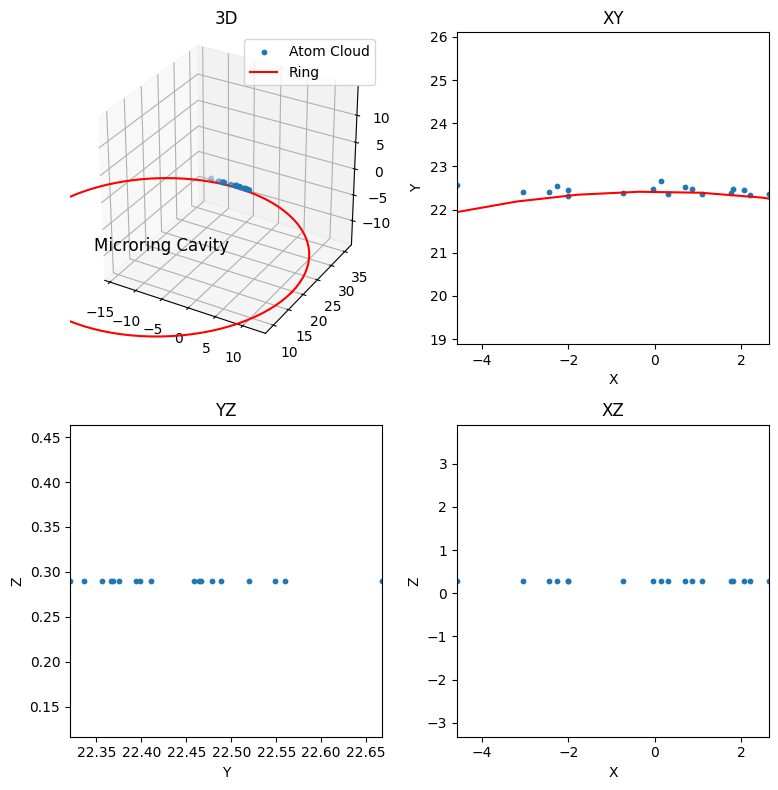

In [8]:
def plot_atoms_with_projections(x, y, z, filename="atoms.png"):
    x, y, z = np.asarray(x), np.asarray(y), np.asarray(z)

    fig = plt.figure(figsize=(8, 8))

    # --- 3D ---
    ax3d = fig.add_subplot(2, 2, 1, projection='3d')
    ax3d.scatter(x, y, z, s=10, label='Atom Cloud')
    # add a ring in the x-y plane with radius = ring_radius
    # draw a circle in the x-y plane with radius = ring_radius
    theta = np.linspace(0, 2*np.pi, 100)
    ax3d.plot(ring_radius * np.cos(theta), ring_radius * np.sin(theta), zs=0, zdir='z', color='r', label='Ring')
    ax3d.text(0, 0, 0, "Microring Cavity", color='black', fontsize=12, ha='center')
    ax3d.legend()

    max_range = np.array([
        x.max()-x.min(),
        y.max()-y.min(),
        z.max()-z.min()
    ]).max() / 2 * 4

    mid_x = (x.max()+x.min())/2
    mid_y = (y.max()+y.min())/2
    mid_z = (z.max()+z.min())/2

    ax3d.set_xlim(mid_x-max_range, mid_x+max_range)
    ax3d.set_ylim(mid_y-max_range, mid_y+max_range)
    ax3d.set_zlim(mid_z-max_range, mid_z+max_range)
    ax3d.set_box_aspect([1,1,1])
    ax3d.set_title("3D")

    # helper to enforce equal scaling in 2D
    def set_equal_2d(ax, a, b):
        max_range = max(a.max()-a.min(), b.max()-b.min()) / 2 #* 10
        mid_a = (a.max()+a.min())/2
        mid_b = (b.max()+b.min())/2
        ax.set_xlim(mid_a-max_range, mid_a+max_range)
        ax.set_ylim(mid_b-max_range, mid_b+max_range)
        ax.set_aspect('equal', adjustable='box')

    # --- XY ---
    ax_xy = fig.add_subplot(2, 2, 2)
    ax_xy.scatter(x, y, s=10)
    set_equal_2d(ax_xy, x, y)
    ax_xy.set_xlabel("X"); ax_xy.set_ylabel("Y")
    ax_xy.set_title("XY")
    ax_xy.plot(ring_radius * np.cos(theta), ring_radius * np.sin(theta), color='r', label='Ring')

    # --- YZ ---
    ax_yz = fig.add_subplot(2, 2, 3)
    ax_yz.scatter(y, z, s=10)
    set_equal_2d(ax_yz, y, z)
    ax_yz.set_xlabel("Y"); ax_yz.set_ylabel("Z")
    ax_yz.set_title("YZ")
    # ax_yz.plot(ring_radius * np.cos(theta), (x0 + rng.lognormal(mean=mu, sigma=sigma, size=N))/lambda_fs, color='r', label='Ring')

    # --- XZ ---
    ax_xz = fig.add_subplot(2, 2, 4)
    ax_xz.scatter(x, z, s=10)
    set_equal_2d(ax_xz, x, z)
    ax_xz.set_xlabel("X"); ax_xz.set_ylabel("Z")
    ax_xz.set_title("XZ")
    # ax_xz.plot(ring_radius * np.cos(theta), (x0 + rng.lognormal(mean=mu, sigma=sigma, size=N))/lambda_fs, color='r', label='Ring')

    plt.tight_layout()
    # plt.savefig(filename, dpi=300)
    plt.show()
    #plt.close()

plot_atoms_with_projections(x, y, z, f"atom_cloud_N={N}_seed={seed}.png")

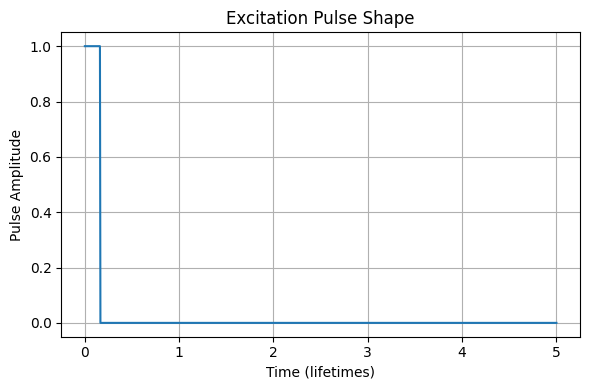

In [9]:
# inversion parameters
# since we start with atoms in their ground state, we will send in a laser pulse from the z direction to excite the atom to the excited state, and then we will let the system evolve under the cooperative decay after the pulse is turned off
initial_state = 'ground'
q = (1., 1j, 0) # polarization of the excitation field, circularly polarized in the x-y plane
alpha_0  = 10 # proportional to the Rabi frequency of the excitation field, in units of the decay rate
t_pulse = 5/30.5 # pulse duration of 5ns compared to the 30.5ns lifetime of the excited state (assuming Cs D2 line)
C1 = 0.4 # single atom cooperativity, defined as the ratio of the decay rate into the waveguide to the total decay rate
# C1 depends on the height of the atom above the waveguide, and the value of 0.4 corresponds to a height of around 200nm for Cs D2 line in a typical nanophotonic waveguide
# Cs = f(z) # cooperative decay rate for each atom in the cloud, which depends on the position of the atom perpendicular to the plane of the waveguide
t0 = 0
tf = 5
Nt = 1001
tlist = np.linspace(t0, tf, Nt)
pulse_shape = np.where(tlist < t_pulse, 1, 0) # square pulse shape for the excitation field
# plot the pulse shape
plt.figure(figsize=(6, 4))
plt.plot(tlist, pulse_shape)
plt.xlabel("Time (lifetimes)")
plt.ylabel("Pulse Amplitude")
plt.title("Excitation Pulse Shape")
plt.grid()
plt.tight_layout()


In [10]:
# parameters for statistics of tracjectories
# since we have a stochastic cloud, we need to run multiple trajectories to get the average behavior of the system, and the distribution of the observables
N_traj_process = 10

## 3) MF2 calculation
- Since we are working with a relatively large number of atoms (~50 in the experiment), we will use a higher order mean field analysis.
- Here, we use a second order mean field (MF2) analysis which keeps track of single atom observables $\sigma^\pm, \sigma^e$ for the coherence and excitation operators of an atom. We also keep track of two-atom variables like $\sigma^+_i\sigma^-_j$. We approximate higher-atom operators using a cumulant expansion. This is called the MF2 approximation which is usually suffecient to capture superradiance photon statistics.
- the dynamical equations are given by the function [rhs_mf2](mf2_func.py) in file mf2_func.py
- We will compare the MF2 calculation to exact calculations based on N=18 atoms below

In [11]:
# variables for MF2
sys_size = 2 * N + 5 * N * (N - 1) // 2
y = np.zeros(sys_size, dtype=complex)
print(f"Approx memory per y: {y.nbytes / 1024 / 1024:.2f} MB")


# where things stored in the vector
idx_e = 0 # e
idx_m = N # sm
idx_ee = 2*N # ee terms
idx_em = 2*N + N*(N-1)//2 # esm terms
idx_me = 2*N + 2* N*(N-1)//2 # sm e terms
idx_mm = 2*N + 3* N*(N-1)//2 # s- s- terms
idx_pm = 2*N + 4* N*(N-1)//2 # s+ s- terms

lut2 = -1 * np.ones((3, 3), dtype=np.int64)
lut2[1, 1] = idx_ee
lut2[0, 1] = idx_me
lut2[1, 0] = idx_em # found these were buggy; change them in other codes
lut2[0, 0] = idx_mm
lut2[2, 0] = idx_pm

lut1 = -1 * np.ones((3), dtype=np.int64)
lut1[0] = idx_m
lut1[1] = idx_e

lut = lut1, lut2

if initial_state == 'inverted':
    # all e and ee terms are 1, all others are 0
    y[:N] = 1.0  # e
    y[idx_ee:idx_em] = 1.0  # sm
    alpha_0 = 0 # no initial pulse

Approx memory per y: 0.01 MB


In [12]:
# observables
# we will track the radiation into excitation of the system, the emission into the waveguide, and the emission into free space
power_fs = np.zeros(Nt) # power emitted into free space
power_wg = np.zeros(Nt) # power emitted into the waveguide
average_excitation = np.zeros(Nt) # average excitation of the atoms, defined as the average of the e terms in the y vector
# a function to calculate these are given by compute_powers in file mf2_func.py, which takes in the y vector and the parameters of the system, and returns the power emitted into free space and the waveguide, and the average excitation of the atoms
average_cooperativty = 0

In [13]:
# main loop
for i in range(N_traj_process):
    print("running trajectory number ", i+1, " out of ", N_traj_process)
    # generate a new cloud for each trajectory
    x_loc = rng.normal(0, rms_along_ring, size=N)
    y_loc = ring_radius + rng.normal(0, rms_transverse, size=N)
    if z_dist_type == 'lognormal':
        z_loc = (x0 + rng.lognormal(mean=mu, sigma=sigma, size=N))/lambda_fs - 0.1014
    elif z_dist_type == 'delta':
        z_loc = np.full(N, 0.290164)
    Cs = f(z_loc)
    print("Average cooperativity for this trajectory:", np.mean(Cs))

    average_cooperativty += np.mean(Cs)
    # atom phases in freespace
    phases = (x_loc * kf, y_loc * kf,z_loc * kf)

    # calculate the freespace coupling matrix for this cloud
    Gfs = ar.Gfs_N(q, phases, N) # freespace G

    # calculate the waveguide coupling matrix for this cloud
    Gr = np.zeros((N,N),dtype=complex)
    for k in range(N):
        for j in range(N):
            Gr[k,j] = np.sqrt(Cs[k]*Cs[j]) * np.cos(kwg * (x[k] - x[j]))
    
    # total coupling matrix is the sum of the freespace and waveguide coupling matrices
    H = (Gfs + Gr)/2

    # exciting laser (propagating in z) phases in freespace
    h = alpha_0 * 1j * np.exp(1j * kf * z)

    # the dy/dt function for the ODE solver, which takes in the current time, the current state vector y, and the parameters of the system, and returns the derivative of y with respect to time
    rhs_with_params = lambda t, y: rhs_mf2(t,y, h, H, N, lut, pulse_type = 'square', tf = t_pulse)

    t_span = (t0 , tf)

    # time the ODE solver to get a sense of how long each trajectory takes, which will help us estimate the total runtime of the program
    start_time = time.time()
    sol = solve_ivp(rhs_with_params, t_span, y, t_eval=tlist, method='RK45',
            dense_output=False, rtol=1e-3, atol=1e-6)
    end_time = time.time()
    print(f"traj {i+1} ran in {end_time - start_time:.4f} seconds")
    print("Memory usage (MB):", process.memory_info().rss / 1024 / 1024)
    start_time = time.time()
    pfs, pwg = compute_powers(Gfs, Gr, sol.y, idx_m, idx_e, idx_pm, pi, N, Nt) # change 0 * alpha_t to consider overall power not just the atoms

    power_fs += pfs
    power_wg += pwg
    average_excitation += np.sum(sol.y[:N, :], axis=0).real / N
    end_time = time.time()
    del sol
    print(f"powers for traj {i+1} ran in {end_time - start_time:.4f} seconds")
    
average_cooperativty /= N_traj_process
print("Average cooperativity over all trajectories:", average_cooperativty)

running trajectory number  1  out of  10
Average cooperativity for this trajectory: 0.39999750344166973
traj 1 ran in 22.9540 seconds
Memory usage (MB): 121.03125
powers for traj 1 ran in 0.3208 seconds
running trajectory number  2  out of  10
Average cooperativity for this trajectory: 0.39999750344166973
traj 2 ran in 1.8522 seconds
Memory usage (MB): 193.34375
powers for traj 2 ran in 0.0037 seconds
running trajectory number  3  out of  10
Average cooperativity for this trajectory: 0.39999750344166973
traj 3 ran in 1.9282 seconds
Memory usage (MB): 198.046875
powers for traj 3 ran in 0.0037 seconds
running trajectory number  4  out of  10
Average cooperativity for this trajectory: 0.39999750344166973
traj 4 ran in 1.5504 seconds
Memory usage (MB): 201.25
powers for traj 4 ran in 0.0042 seconds
running trajectory number  5  out of  10
Average cooperativity for this trajectory: 0.39999750344166973
traj 5 ran in 14.1662 seconds
Memory usage (MB): 191.03125
powers for traj 5 ran in 0.003

In [14]:
data = {
    't': tlist,
    'power_fs': power_fs/N_traj_process,
    'power_wg': power_wg/N_traj_process,
    'average_excitation': average_excitation/N_traj_process,
    'pulse_t': pulse_shape,
}

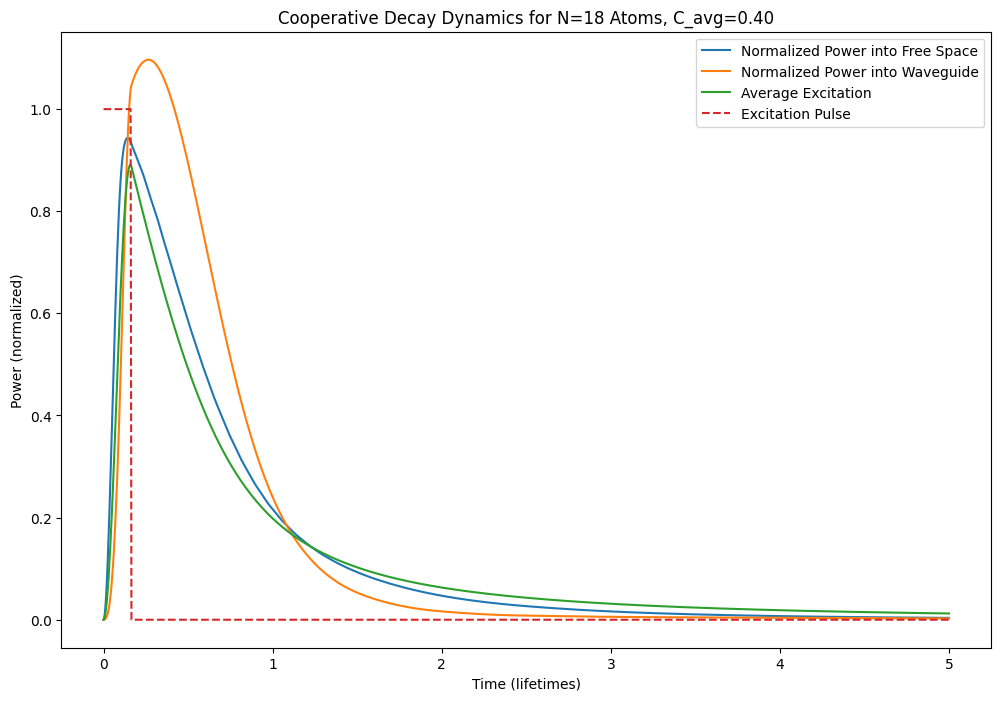

In [15]:
# plot the results
plt.figure(figsize=(12, 8))
# plt.subplot(2, 1, 1)
plt.plot(tlist, data['power_fs']/N, label='Normalized Power into Free Space')
plt.plot(tlist, data['power_wg']/(N*average_cooperativty), label='Normalized Power into Waveguide')
plt.plot(tlist, data['average_excitation'], label='Average Excitation')
plt.plot(tlist, data['pulse_t'], label='Excitation Pulse', linestyle='--')
plt.xlabel("Time (lifetimes)")
plt.ylabel("Power (normalized)")
plt.title(f"Cooperative Decay Dynamics for N={N} Atoms, C_avg={C1:.2f}")
plt.legend()

## 3a) Selective superadinace
- not at the end of the pulse, the atoms are about 90% excited
- note that if the atoms are independent of each other (no interaction), the photon rates decay exponentially after the excitation pulse ends
- from the normalized photon rates into the waveguide and freespace, we can see at the end of the excitation pulse the normalized rate increases appreciably for the waveguide before it decreases while it decreases right away for freespace. This indicates the atoms are aligning their phases to constructively interfere giving a burst into the waveguide. This constructive interference is more prominent for the waveguide than for freespace, indicating channel competition, and selective superadinace into the waveguide.


## 3b) Washing out selective superadinace with stochastic z-spread
- now if you rerun the notebook but choosing a varying z position (lognormal distribution) as usually happening in the experiment, the selective superadiance is wached out.

## 4) Comparison with exact method (MC simulation) for delta z distribution
- below, we benchmark the MF2 method by comparing with a simulation based on MC trajectories for 18 atoms
- while the MC trajectory is exact, it still needs lots of trajectories to get low statistical noise, here only use 400 trajecories, so shot to shot noise is manifest
- for reference, for a monte carlo trajectory, we use around 60 GB of RAM and 20 mins of compute time (using a single core)
- for MF2, as shown above, the maximum RAM utility is around 0.3 GB (the state vector is actually much small and is a fraction of a MB), and only a few seconds of compute are used
- this shows the power of the approximation regarding the compute resource effiency

In [16]:
# load the data for MC calculation
mc_data = np.loadtxt(f"output_data/me_driven_N=18_C=0.4_method=MC_Ntraj=394.csv")
mc_data = {
    't': mc_data[:, 0],
    'power_fs': mc_data[:, 1],
    'power_wg': mc_data[:, 2],
    'average_excitation': mc_data[:, 3],
    'power_fs_error': mc_data[:, 4],
    'power_wg_error': mc_data[:, 5],
    'average_excitation_error': mc_data[:, 6],
}

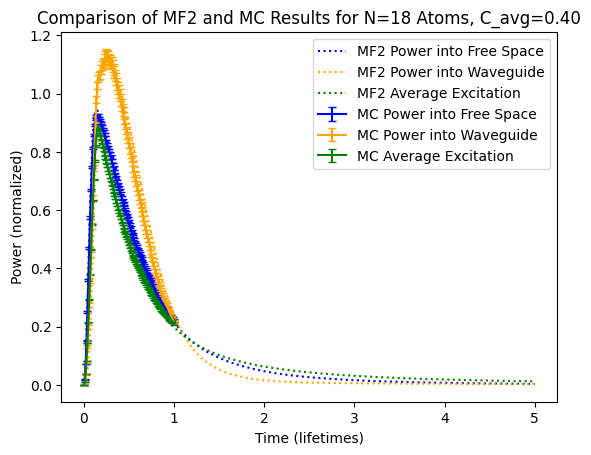

In [17]:
# plot the MC results for comparison against the MF2 results

# calculate the errors for the MC results
power_fs_error = mc_data['power_fs_error'] / N
power_wg_error = mc_data['power_wg_error'] / (N*C1)
average_excitation_error = mc_data['average_excitation_error']

plt.errorbar(mc_data['t'], mc_data['power_fs']/N, yerr=power_fs_error, label='MC Power into Free Space', linestyle='-', color='blue', capsize=3)
plt.errorbar(mc_data['t'], mc_data['power_wg']/(N*C1), yerr=power_wg_error, label='MC Power into Waveguide', linestyle='-', color='orange', capsize=3)
plt.errorbar(mc_data['t'], mc_data['average_excitation'], yerr=average_excitation_error, label='MC Average Excitation', linestyle='-', color='green', capsize=3)

plt.plot(tlist, data['power_fs']/N, label='MF2 Power into Free Space', linestyle=':', color='blue')
plt.plot(tlist, data['power_wg']/(N*C1), label='MF2 Power into Waveguide', linestyle=':', color='orange')
plt.plot(tlist, data['average_excitation'], label='MF2 Average Excitation', linestyle=':', color='green')

plt.xlabel("Time (lifetimes)")
plt.ylabel("Power (normalized)")
plt.title(f"Comparison of MF2 and MC Results for N={N} Atoms, C_avg={C_avg:.2f}")
plt.legend()


## 4a) Agreement of MF2 with MC
- as we notice from the comparison above, MF2 captures the dynamics pretty reliably